<a href="https://colab.research.google.com/github/DrFaus/EstadisticaInferencial2026A/blob/main/EstadisticaInferencial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Prueba de hipótesis para la media una muestra

## Importar datos, variable `data`

In [6]:
# Importar datos
import pandas as pd
data = pd.Series([10.2, 10.4, 9.9, 10.3, 10.5], name="peso en mg")
data

,peso en mg
0,10.2
1,10.4
2,9.9
3,10.3
4,10.5


## Descripción de datos

In [9]:
data.describe()

,peso en mg
count,5.000000
mean,10.260000
std,0.230217
min,9.900000
25%,10.200000
50%,10.300000
75%,10.400000
max,10.500000


## Prueba de normalidad (Shapiro-Wilk), gráfico cuantil-cuantil e histograma

valor-p (Shapiro) = 0.6852955131798772


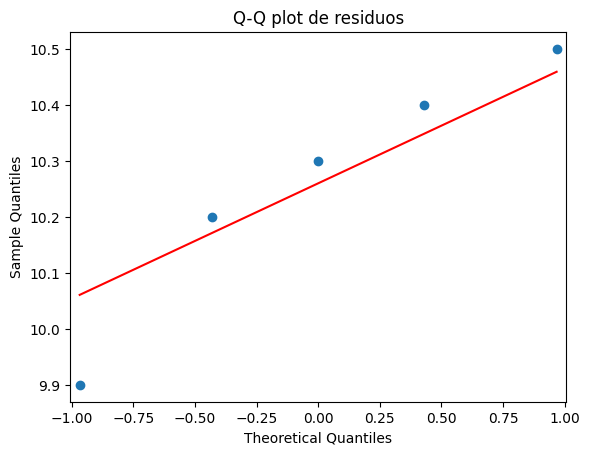

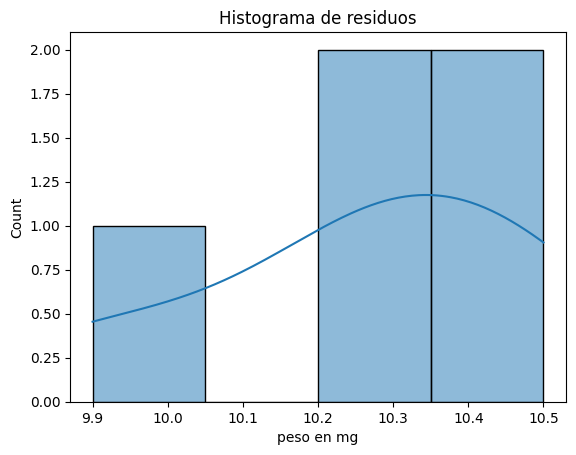

In [7]:
# Prueba de normalidad

from scipy.stats import shapiro
import matplotlib.pyplot as plt
import statsmodels.api as sm
import seaborn as sns

# Prueba de Shapiro-Wilk
# Hipótesis Nula H0: Los datos siguen una distribución normal.
#                    No existen diferencias significativas entre la
#                    distribución de la muestra y una distribución normal.
# Hipótesis Alternativa H1: Los datos no siguen una distribución normal.
#                    La distribución de la muestra difiere significativamente
#                    de una distribución normal.

stat, valor_p_sh = shapiro(data)
print(f"valor-p (Shapiro) = {valor_p_sh}")

# Visualización: Q-Q plot
sm.qqplot(data, line='s')
plt.title("Q-Q plot de residuos")
plt.show()

# Histograma
sns.histplot(data, kde=True)
plt.title("Histograma de residuos")
plt.show()

## Prueba de hipótesis basada en código

In [16]:
import numpy as np
import scipy.stats as stats

# H0: μ = 10
mu_hipotetica = 10

alt = "less"       # H1: μ < 10
alt = "two-sided"  # H1: μ ≠ 10
alt = "greater"    # H1: μ > 10

# Ejecutar la prueba t de una muestra
t_estadistico, p_valor = stats.ttest_1samp(
    data,
    popmean=mu_hipotetica,
    alternative = alt)

# Mostrar resultados e interpretación
print(f"Estadístico t: {t_estadistico:.4f}")
print(f"p-valor: {p_valor:.4f}")

Estadístico t: 2.5253
p-valor: 0.0325


## Gráfico de la prueba de hipótesis

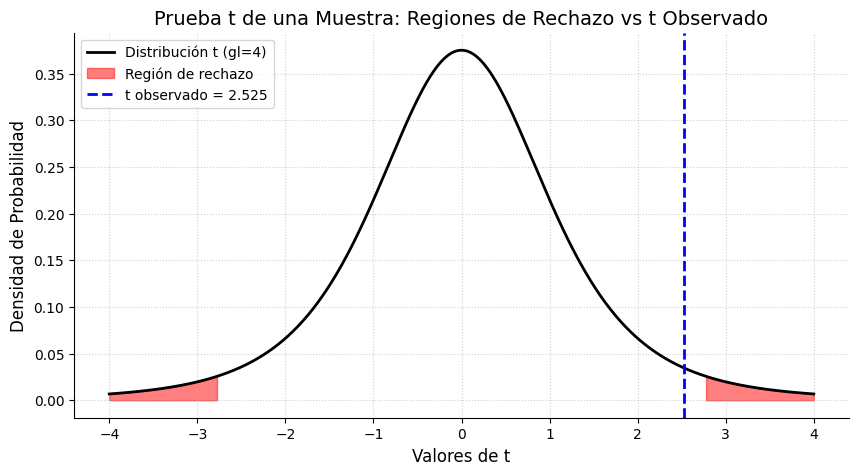

In [29]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

mu_hipotetica = 10
alpha = 0.05

# Calcular estadísticos
n = data.size
gl = n - 1  # grados de libertad
t_estadistico, p_valor = stats.ttest_1samp(data, popmean=mu_hipotetica)

tipo_prueba = 0
# -1: H1: μ < 10
#  0: H1: μ ≠ 10
#  1: H1: μ > 10

# H1: μ < 10
if tipo_prueba < 0:
  t_critico = stats.t.ppf(alpha, df=gl)
# H1: μ ≠ 10
elif tipo_prueba == 0:
  t_critico = stats.t.ppf(1 - alpha/2, df=gl)
# H1: μ > 10
elif tipo_prueba > 0:
  t_critico = stats.t.ppf(1 - alpha, df=gl)

# 3. Configurar el eje X para la distribución t
x = np.linspace(-4, 4, 1000)
y = stats.t.pdf(x, df=gl)

# 4. Crear el gráfico
plt.figure(figsize=(10, 5))
plt.plot(x, y, label=f'Distribución t (gl={gl})', color='black', lw=2)

# H1: μ < 10
if tipo_prueba < 0:
  x_izq = np.linspace(-4, -t_critico, 100)
  plt.fill_between(x_izq, stats.t.pdf(x_izq, df=gl), color='red', alpha=0.5, label='Región de rechazo')

# H1: μ ≠ 10
elif tipo_prueba == 0:
  x_izq = np.linspace(-4, -t_critico, 100)
  plt.fill_between(x_izq, stats.t.pdf(x_izq, df=gl), color='red', alpha=0.5, label='Región de rechazo')
  x_der = np.linspace(t_critico, 4, 100)
  plt.fill_between(x_der, stats.t.pdf(x_der, df=gl), color='red', alpha=0.5)

# H1: μ > 10
elif tipo_prueba > 0:
  x_der = np.linspace(t_critico, 4, 100)
  plt.fill_between(x_der, stats.t.pdf(x_der, df=gl), color='red', alpha=0.5, label="Región de rechazo")


# Dibujar el Estadístico t observado
plt.axvline(t_estadistico, color='blue', linestyle='--', lw=2,
            label=f't observado = {t_estadistico:.3f}')

# Personalización del gráfico
plt.gca().spines[["top", "right"]].set_visible(False)
plt.title('Prueba t de una Muestra: Regiones de Rechazo vs t Observado', fontsize=14)
plt.xlabel('Valores de t', fontsize=12)
plt.ylabel('Densidad de Probabilidad', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)

if t_critico < 0:
  plt.legend(loc='upper right')
else:
  plt.legend(loc='upper left')

## Prueba de hipótesis basada en cálculos

In [39]:
from math import sqrt

x_promedio = data.mean()  # promedio de la muestra
s = data.std()            # desviación estándar
mu_hipotetica = 10

n = data.size
gl = n - 1

t = (x_promedio - mu_hipotetica) / (s / sqrt(n))

# Obtener la t crítica
area_1 = 0.05     # alpha, alpha/2 o 1-alpha
t_critico = stats.t.ppf(area_1, df=gl)

# Obtener el área bajo la curva desde -infinito hasta t
area_2 = stats.t.cdf(t, df = gl)   # con esto se obtiene el valor-p

print(f"Estadístico t: {t: 0.4f}")
print(f"t crítico: {t_critico: 0.4f}")
print(f"Área bajo la curva: {area_2: 0.4f}")

Estadístico t:  2.5253
t crítico: -2.1318
Área bajo la curva:  0.9675


# Prueba de hipótesis varianza, de una muestra

## Importar datos, variable `data`

In [40]:
# Importar datos
import pandas as pd
data = pd.Series([10.2, 10.4, 9.9, 10.3, 10.5], name="peso en mg")
data

,peso en mg
0,10.2
1,10.4
2,9.9
3,10.3
4,10.5


## Descripción de datos

In [41]:
data.describe()

,peso en mg
count,5.000000
mean,10.260000
std,0.230217
min,9.900000
25%,10.200000
50%,10.300000
75%,10.400000
max,10.500000


## Prueba de normalidad (Shapiro-Wilk), gráfico cuantil-cuantil e histograma

valor-p (Shapiro) = 0.6852955131798772


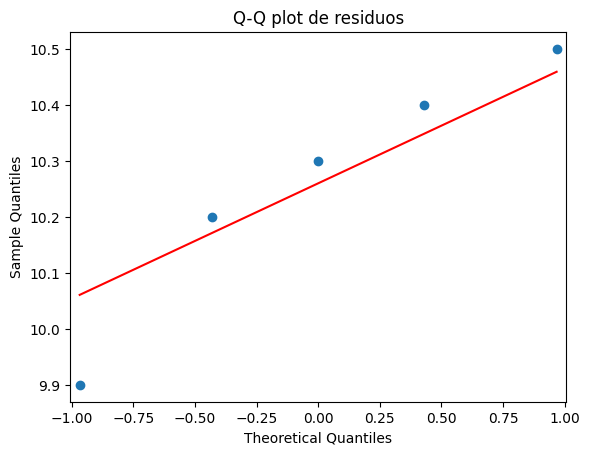

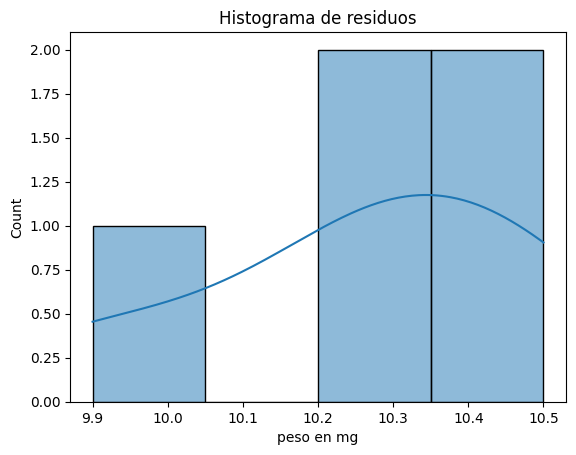

In [42]:
# Prueba de normalidad

from scipy.stats import shapiro
import matplotlib.pyplot as plt
import statsmodels.api as sm
import seaborn as sns

# Prueba de Shapiro-Wilk
# Hipótesis Nula H0: Los datos siguen una distribución normal.
#                    No existen diferencias significativas entre la
#                    distribución de la muestra y una distribución normal.
# Hipótesis Alternativa H1: Los datos no siguen una distribución normal.
#                    La distribución de la muestra difiere significativamente
#                    de una distribución normal.

stat, valor_p_sh = shapiro(data)
print(f"valor-p (Shapiro) = {valor_p_sh}")

# Visualización: Q-Q plot
sm.qqplot(data, line='s')
plt.title("Q-Q plot de residuos")
plt.show()

# Histograma
sns.histplot(data, kde=True)
plt.title("Histograma de residuos")
plt.show()

## Prueba de hipótesis basada en código


In [44]:
import numpy as np
import scipy.stats as stats

# H0: σ² = 0.04
var_hipotetica = 0.04

# Tamaño de muestra y varianza muestral
n = len(data)
s2 = np.var(data, ddof=1)

# Grados de libertad
gl = n - 1

# Estadístico chi-cuadrada
chi2_estadistico = (gl * s2) / var_hipotetica

# Seleccionar hipótesis alternativa

alt = "less"       # H1: σ² < 0.04
alt = "two-sided"  # H1: σ² ≠ 0.04
alt = "greater"    # H1: σ² > 0.04


# Calcular p-valor
if alt == "less":
    p_valor = stats.chi2.cdf(chi2_estadistico, df=gl)

elif alt == "greater":
    p_valor = stats.chi2.sf(chi2_estadistico, df=gl)

elif alt == "two-sided":
    p_izquierda = stats.chi2.cdf(chi2_estadistico, df=gl)
    p_derecha = stats.chi2.sf(chi2_estadistico, df=gl)
    p_valor = 2 * min(p_izquierda, p_derecha)

# Mostrar resultados
print(f"Varianza muestral: {s2:.4f}")
print(f"Estadístico χ²: {chi2_estadistico:.4f}")
print(f"p-valor: {p_valor:.4f}")

Varianza muestral: 0.0530
Estadístico χ²: 5.3000
p-valor: 0.2579


## Gráfico de la prueba de hipótesis

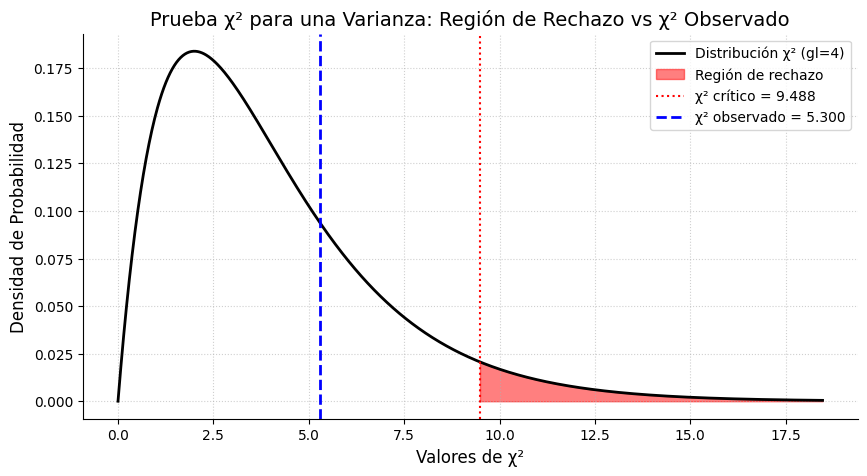

In [46]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

# H0: σ² = 0.04
var_hipotetica = 0.04
alpha = 0.05

# Calcular estadísticos
n = data.size
gl = n - 1

# Varianza muestral
s2 = data.var()

# Estadístico chi-cuadrada observado
chi2_estadistico = (gl * s2) / var_hipotetica

tipo_prueba = 1
# -1: H1: σ² < 0.04
#  0: H1: σ² ≠ 0.04
#  1: H1: σ² > 0.04


# Calcular valores críticos

# H1: σ² < 16
if tipo_prueba < 0:
    chi2_critico_izq = stats.chi2.ppf(alpha, df=gl)

# H1: σ² ≠ 16
elif tipo_prueba == 0:
    chi2_critico_izq = stats.chi2.ppf(alpha/2, df=gl)
    chi2_critico_der = stats.chi2.ppf(1 - alpha/2, df=gl)

# H1: σ² > 16
elif tipo_prueba > 0:
    chi2_critico_der = stats.chi2.ppf(1 - alpha, df=gl)


# Configurar el eje X para la distribución chi-cuadrada
x_max = stats.chi2.ppf(0.999, df=gl)

# Asegurar que aparezca el estadístico observado
x_max = max(x_max, chi2_estadistico * 1.15)

x = np.linspace(0, x_max, 1000)
y = stats.chi2.pdf(x, df=gl)


# Crear el gráfico
plt.figure(figsize=(10, 5))

plt.plot(
    x, y,
    label=f'Distribución χ² (gl={gl})',
    color='black',
    lw=2
)


# H1: σ² < 16
if tipo_prueba < 0:

    x_izq = np.linspace(0, chi2_critico_izq, 200)

    plt.fill_between(
        x_izq,
        stats.chi2.pdf(x_izq, df=gl),
        color='red',
        alpha=0.5,
        label='Región de rechazo'
    )

    plt.axvline(
        chi2_critico_izq,
        color='red',
        linestyle=':',
        label=f'χ² crítico = {chi2_critico_izq:.3f}'
    )


# H1: σ² ≠ 16
elif tipo_prueba == 0:

    # Cola izquierda
    x_izq = np.linspace(0, chi2_critico_izq, 200)

    plt.fill_between(
        x_izq,
        stats.chi2.pdf(x_izq, df=gl),
        color='red',
        alpha=0.5,
        label='Región de rechazo'
    )

    # Cola derecha
    x_der = np.linspace(chi2_critico_der, x_max, 200)

    plt.fill_between(
        x_der,
        stats.chi2.pdf(x_der, df=gl),
        color='red',
        alpha=0.5
    )

    plt.axvline(
        chi2_critico_izq,
        color='red',
        linestyle=':',
        label=f'χ² crítico izq. = {chi2_critico_izq:.3f}'
    )

    plt.axvline(
        chi2_critico_der,
        color='red',
        linestyle=':',
        label=f'χ² crítico der. = {chi2_critico_der:.3f}'
    )


# H1: σ² > 16
elif tipo_prueba > 0:

    x_der = np.linspace(chi2_critico_der, x_max, 200)

    plt.fill_between(
        x_der,
        stats.chi2.pdf(x_der, df=gl),
        color='red',
        alpha=0.5,
        label='Región de rechazo'
    )

    plt.axvline(
        chi2_critico_der,
        color='red',
        linestyle=':',
        label=f'χ² crítico = {chi2_critico_der:.3f}'
    )


# Dibujar el estadístico chi-cuadrada observado
plt.axvline(
    chi2_estadistico,
    color='blue',
    linestyle='--',
    lw=2,
    label=f'χ² observado = {chi2_estadistico:.3f}'
)


# Personalización
plt.gca().spines[["top", "right"]].set_visible(False)

plt.title(
    'Prueba χ² para una Varianza: Región de Rechazo vs χ² Observado',
    fontsize=14
)

plt.xlabel('Valores de χ²', fontsize=12)
plt.ylabel('Densidad de Probabilidad', fontsize=12)

plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()

plt.show()

## Prueba de hipótesis basada en cálculos

In [48]:
import numpy as np
import scipy.stats as stats

# H0: σ² = 0.04
var_hipotetica = 0.04

# Tamaño de muestra
n = data.size
gl = n - 1

# Varianza muestral
s2 = np.var(data, ddof=1)

# Estadístico chi-cuadrada
chi2 = (gl * s2) / var_hipotetica

# Obtener chi-cuadrada crítica
area_1 = 0.95     # alpha, alpha/2, 1-alpha/2 o 1-alpha
chi2_critico = stats.chi2.ppf(area_1, df=gl)

# Obtener el área bajo la curva
# desde 0 hasta chi2 observado
area_2 = stats.chi2.cdf(chi2, df=gl)

print(f"Varianza muestral: {s2:0.4f}")
print(f"Estadístico χ²: {chi2:0.4f}")
print(f"χ² crítico: {chi2_critico:0.4f}")
print(f"Área bajo la curva: {area_2:0.4f}")

Varianza muestral: 0.0530
Estadístico χ²: 5.3000
χ² crítico: 9.4877
Área bajo la curva: 0.7421


# Prueba de hipótesis, dos muestras no pareadas

## Importación de datos

In [49]:
import pandas as pd
from io import StringIO

datos = '''
grupo,valor
A,52
A,55
A,57
A,54
A,59
A,61
A,58
A,56
A,60
A,63
A,57
A,62
A,59
B,48
B,51
B,53
B,50
B,56
B,55
B,52
B,54
B,57
B,49
B,58
B,53
B,55
'''

datos = datos.replace(" ", "")

df = pd.read_csv(StringIO(datos))
df.reset_index(drop=True, inplace=True)

df

,grupo,valor
0,A,52
1,A,55
2,A,57
3,A,54
4,A,59
5,A,61
6,A,58
7,A,56
8,A,60
9,A,63


In [51]:
muestra_A = df[df["grupo"] == "A"]["valor"]
muestra_B = df[df["grupo"] == "B"]["valor"]

## Prueba de normalidad

### Muestra A

valor-p (Shapiro) = 0.9975604599137069


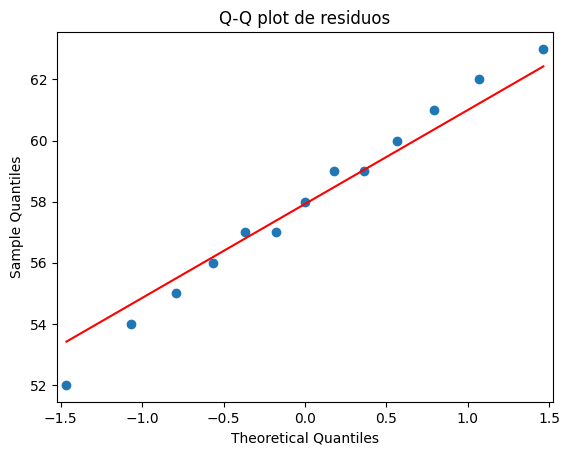

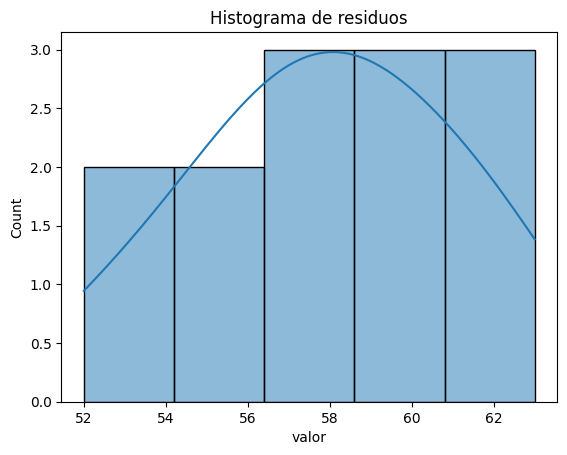

In [52]:
# Prueba de normalidad

from scipy.stats import shapiro
import matplotlib.pyplot as plt
import statsmodels.api as sm
import seaborn as sns

# Prueba de Shapiro-Wilk
# Hipótesis Nula H0: Los datos siguen una distribución normal.
#                    No existen diferencias significativas entre la
#                    distribución de la muestra y una distribución normal.
# Hipótesis Alternativa H1: Los datos no siguen una distribución normal.
#                    La distribución de la muestra difiere significativamente
#                    de una distribución normal.

stat, valor_p_sh = shapiro(muestra_A)
print(f"valor-p (Shapiro) = {valor_p_sh}")

# Visualización: Q-Q plot
sm.qqplot(muestra_A, line='s')
plt.title("Q-Q plot de residuos")
plt.show()

# Histograma
sns.histplot(muestra_A, kde=True)
plt.title("Histograma de residuos")
plt.show()

### Muestra B

valor-p (Shapiro) = 0.9517600920616711


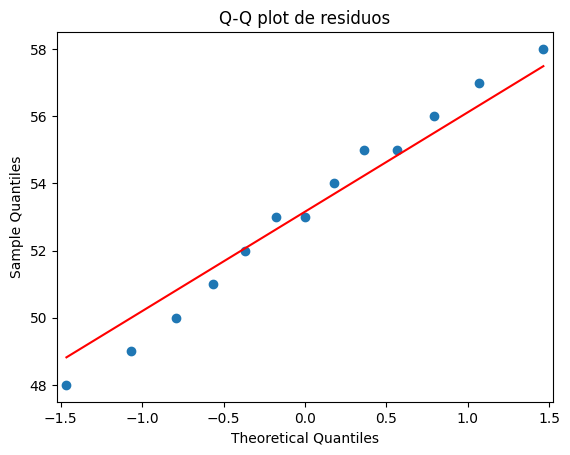

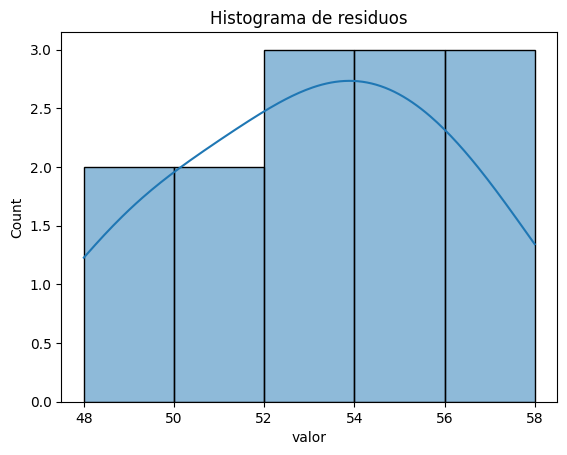

In [53]:
# Prueba de normalidad

from scipy.stats import shapiro
import matplotlib.pyplot as plt
import statsmodels.api as sm
import seaborn as sns

# Prueba de Shapiro-Wilk
# Hipótesis Nula H0: Los datos siguen una distribución normal.
#                    No existen diferencias significativas entre la
#                    distribución de la muestra y una distribución normal.
# Hipótesis Alternativa H1: Los datos no siguen una distribución normal.
#                    La distribución de la muestra difiere significativamente
#                    de una distribución normal.

stat, valor_p_sh = shapiro(muestra_B)
print(f"valor-p (Shapiro) = {valor_p_sh}")

# Visualización: Q-Q plot
sm.qqplot(muestra_B, line='s')
plt.title("Q-Q plot de residuos")
plt.show()

# Histograma
sns.histplot(muestra_B, kde=True)
plt.title("Histograma de residuos")
plt.show()

## Prueba de homoscedasticidad con Levene

In [54]:
from scipy import stats

# H0: σ²A = σ²B
# H1: σ²A ≠ σ²B

estadistico, p_valor = stats.levene(muestra_A, muestra_B)

print("Estadístico de Levene:", estadistico)
print("Valor-p:", p_valor)

Estadístico de Levene: 0.012396694214875947
Valor-p: 0.9122723148660025


## Prueba de homoscedasticidad con F

In [55]:
import numpy as np
import scipy.stats as stats

# H0: σ²A = σ²B

alt = "less"       # H1: σ²A < σ²B
alt = "two-sided"  # H1: σ²A ≠ σ²B
alt = "greater"    # H1: σ²A > σ²B


# Tamaños de muestra
n_A = muestra_A.size
n_B = muestra_B.size

# Varianzas muestrales
s2_A = muestra_A.var()
s2_B = muestra_B.var()

# Estadístico F
F_estadistico = s2_A / s2_B

# Grados de libertad
gl_1 = n_A - 1
gl_2 = n_B - 1


# Calcular p-valor
if alt == "less":
    p_valor = stats.f.cdf(
        F_estadistico,
        dfn=gl_1,
        dfd=gl_2
    )

elif alt == "greater":
    p_valor = stats.f.sf(
        F_estadistico,
        dfn=gl_1,
        dfd=gl_2
    )

elif alt == "two-sided":
    cola_izquierda = stats.f.cdf(
        F_estadistico,
        dfn=gl_1,
        dfd=gl_2
    )

    cola_derecha = stats.f.sf(
        F_estadistico,
        dfn=gl_1,
        dfd=gl_2
    )

    p_valor = 2 * min(cola_izquierda, cola_derecha)
    p_valor = min(p_valor, 1)


# Mostrar resultados
print(f"Estadístico F: {F_estadistico:.4f}")
print(f"p-valor: {p_valor:.4f}")

Estadístico F: 1.0812
p-valor: 0.8947


## Gráfico de la prueba de homoscedasticidad con F

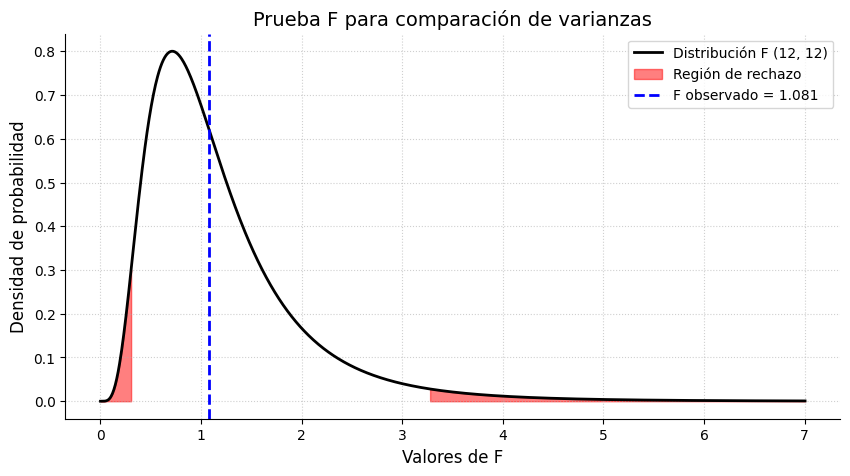

F observado: 1.0812
p-valor: 0.8947


In [57]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

alpha = 0.05

# Calcular estadísticos
n_A = muestra_A.size
n_B = muestra_B.size

gl_1 = n_A - 1
gl_2 = n_B - 1

s2_A = muestra_A.var()
s2_B = muestra_B.var()

F_estadistico = s2_A / s2_B

tipo_prueba = 0
# -1: H1: σ²A < σ²B
#  0: H1: σ²A ≠ σ²B
#  1: H1: σ²A > σ²B


# H1: σ²A < σ²B
if tipo_prueba < 0:
    F_critico = stats.f.ppf(alpha, dfn=gl_1, dfd=gl_2)

    p_valor = stats.f.cdf(
        F_estadistico,
        dfn=gl_1,
        dfd=gl_2
    )


# H1: σ²A ≠ σ²B
elif tipo_prueba == 0:
    F_critico_izq = stats.f.ppf(
        alpha / 2,
        dfn=gl_1,
        dfd=gl_2
    )

    F_critico_der = stats.f.ppf(
        1 - alpha / 2,
        dfn=gl_1,
        dfd=gl_2
    )

    cola_izq = stats.f.cdf(
        F_estadistico,
        dfn=gl_1,
        dfd=gl_2
    )

    cola_der = stats.f.sf(
        F_estadistico,
        dfn=gl_1,
        dfd=gl_2
    )

    p_valor = 2 * min(cola_izq, cola_der)
    p_valor = min(p_valor, 1)


# H1: σ²A > σ²B
elif tipo_prueba > 0:
    F_critico = stats.f.ppf(
        1 - alpha,
        dfn=gl_1,
        dfd=gl_2
    )

    p_valor = stats.f.sf(
        F_estadistico,
        dfn=gl_1,
        dfd=gl_2
    )


# Configurar eje X
limite = stats.f.ppf(0.999, dfn=gl_1, dfd=gl_2)

x = np.linspace(0.001, limite, 1000)
y = stats.f.pdf(x, dfn=gl_1, dfd=gl_2)


# Crear gráfico
plt.figure(figsize=(10, 5))

plt.plot(
    x,
    y,
    color="black",
    lw=2,
    label=f"Distribución F ({gl_1}, {gl_2})"
)


# H1: σ²A < σ²B
if tipo_prueba < 0:

    x_izq = np.linspace(0.001, F_critico, 200)

    plt.fill_between(
        x_izq,
        stats.f.pdf(x_izq, dfn=gl_1, dfd=gl_2),
        color="red",
        alpha=0.5,
        label="Región de rechazo"
    )


# H1: σ²A ≠ σ²B
elif tipo_prueba == 0:

    x_izq = np.linspace(0.001, F_critico_izq, 200)

    plt.fill_between(
        x_izq,
        stats.f.pdf(x_izq, dfn=gl_1, dfd=gl_2),
        color="red",
        alpha=0.5,
        label="Región de rechazo"
    )

    x_der = np.linspace(F_critico_der, limite, 200)

    plt.fill_between(
        x_der,
        stats.f.pdf(x_der, dfn=gl_1, dfd=gl_2),
        color="red",
        alpha=0.5
    )


# H1: σ²A > σ²B
elif tipo_prueba > 0:

    x_der = np.linspace(F_critico, limite, 200)

    plt.fill_between(
        x_der,
        stats.f.pdf(x_der, dfn=gl_1, dfd=gl_2),
        color="red",
        alpha=0.5,
        label="Región de rechazo"
    )


# Dibujar estadístico F observado
plt.axvline(
    F_estadistico,
    color="blue",
    linestyle="--",
    lw=2,
    label=f"F observado = {F_estadistico:.3f}"
)


# Personalización
plt.gca().spines[["top", "right"]].set_visible(False)

plt.title(
    "Prueba F para comparación de varianzas",
    fontsize=14
)

plt.xlabel("Valores de F", fontsize=12)
plt.ylabel("Densidad de probabilidad", fontsize=12)

plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()

plt.show()


print(f"F observado: {F_estadistico:.4f}")
print(f"p-valor: {p_valor:.4f}")

## Prueba de diferencia de medias

In [58]:
import numpy as np
import scipy.stats as stats

# H0: μA = μB
alt = "less"      # H1: μA < μB
alt = "two-sided" # H1: μA ≠ μB
alt = "greater"   # H1: μA > μB

# Homoscedasticidad
# True  -> se asumen varianzas iguales
# False -> no se asumen varianzas iguales (Welch)
homoscedasticidad = True

# Ejecutar prueba t para dos muestras independientes
t_estadistico, p_valor = stats.ttest_ind(
    muestra_A,
    muestra_B,
    equal_var=homoscedasticidad,
    alternative=alt
)

# Mostrar resultados
print(f"Estadístico t: {t_estadistico:.4f}")
print(f"p-valor: {p_valor:.4f}")

Estadístico t: 3.8725
p-valor: 0.0004


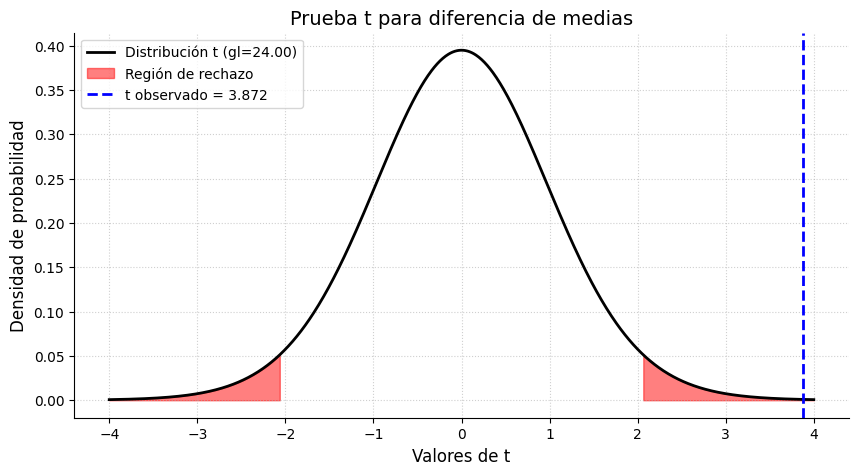

t observado: 3.8725
Grados de libertad: 24.0000
p-valor: 0.0007


In [59]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

alpha = 0.05

# Seleccionar supuesto de varianzas
homoscedasticidad = True
# True  -> varianzas iguales
# False -> varianzas diferentes (Welch)

tipo_prueba = 0
# -1: H1: μA < μB
#  0: H1: μA ≠ μB
#  1: H1: μA > μB


# Tamaños de muestra
n_A = muestra_A.size
n_B = muestra_B.size

# Varianzas
s2_A = muestra_A.var()
s2_B = muestra_B.var()


# Grados de libertad
if homoscedasticidad:
    gl = n_A + n_B - 2
else:
    numerador = (s2_A / n_A + s2_B / n_B)**2
    denominador = (
        (s2_A / n_A)**2 / (n_A - 1)
        +
        (s2_B / n_B)**2 / (n_B - 1)
    )
    gl = numerador / denominador

# Seleccionar alternativa
if tipo_prueba < 0:
    alternativa = "less"

elif tipo_prueba == 0:
    alternativa = "two-sided"

else:
    alternativa = "greater"


# Ejecutar prueba t
t_estadistico, p_valor = stats.ttest_ind(
    muestra_A,
    muestra_B,
    equal_var=homoscedasticidad,
    alternative=alternativa
)


# Obtener valores críticos

# H1: μA < μB
if tipo_prueba < 0:

    t_critico = stats.t.ppf(
        alpha,
        df=gl
    )


# H1: μA ≠ μB
elif tipo_prueba == 0:

    t_critico = stats.t.ppf(
        1 - alpha / 2,
        df=gl
    )


# H1: μA > μB
elif tipo_prueba > 0:

    t_critico = stats.t.ppf(
        1 - alpha,
        df=gl
    )


# Configurar eje X
x = np.linspace(-4, 4, 1000)

y = stats.t.pdf(
    x,
    df=gl
)


# Crear gráfico
plt.figure(figsize=(10, 5))

plt.plot(
    x,
    y,
    color="black",
    lw=2,
    label=f"Distribución t (gl={gl:.2f})"
)


# H1: μA < μB
if tipo_prueba < 0:

    x_izq = np.linspace(-4, t_critico, 200)

    plt.fill_between(
        x_izq,
        stats.t.pdf(x_izq, df=gl),
        color="red",
        alpha=0.5,
        label="Región de rechazo"
    )


# H1: μA ≠ μB
elif tipo_prueba == 0:

    x_izq = np.linspace(-4, -t_critico, 200)

    plt.fill_between(
        x_izq,
        stats.t.pdf(x_izq, df=gl),
        color="red",
        alpha=0.5,
        label="Región de rechazo"
    )

    x_der = np.linspace(t_critico, 4, 200)

    plt.fill_between(
        x_der,
        stats.t.pdf(x_der, df=gl),
        color="red",
        alpha=0.5
    )


# H1: μA > μB
elif tipo_prueba > 0:

    x_der = np.linspace(t_critico, 4, 200)

    plt.fill_between(
        x_der,
        stats.t.pdf(x_der, df=gl),
        color="red",
        alpha=0.5,
        label="Región de rechazo"
    )


# Dibujar estadístico t observado
plt.axvline(
    t_estadistico,
    color="blue",
    linestyle="--",
    lw=2,
    label=f"t observado = {t_estadistico:.3f}"
)


# Personalización
plt.gca().spines[["top", "right"]].set_visible(False)

plt.title(
    "Prueba t para diferencia de medias",
    fontsize=14
)

plt.xlabel("Valores de t", fontsize=12)
plt.ylabel("Densidad de probabilidad", fontsize=12)

plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()

plt.show()


print(f"t observado: {t_estadistico:.4f}")
print(f"Grados de libertad: {gl:.4f}")
print(f"p-valor: {p_valor:.4f}")